In [1]:
pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
print(df.shape)  # expect (7043, 21)

(7043, 21)


In [2]:
# 1. First look
print(df.head())
df.info()

# 2. Churn rate
print(df["Churn"].value_counts(normalize=True))

# 3. Clean TotalCharges (it has blank values stored as text)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())

# 4. Drop the ~11 blank rows and the ID column
df = df.dropna(subset=["TotalCharges"])
df = df.drop(columns=["customerID"])
print(df.shape)

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [3]:
from sklearn.model_selection import train_test_split

# Target: Yes/No -> 1/0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# Convert text columns to numbers (one-hot encoding)
df_encoded = pd.get_dummies(df, drop_first=True)

# Features and target
X = df_encoded.drop("Churn", axis=1)
y = df_encoded["Churn"]

# 80/20 split, keeping the churn ratio equal in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())  # both should be ~0.27

(5625, 30) (1407, 30)
0.2657777777777778 0.2658137882018479


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

lr = LogisticRegression(max_iter=1000, class_weight="balanced")
lr.fit(X_train_s, y_train)

pred = lr.predict(X_test_s)
print(classification_report(y_test, pred))
print("ROC-AUC:", roc_auc_score(y_test, lr.predict_proba(X_test_s)[:, 1]))

              precision    recall  f1-score   support

           0       0.91      0.70      0.79      1033
           1       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407

ROC-AUC: 0.8349765233911922


In [5]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import recall_score, f1_score, accuracy_score

# Ratio used to handle imbalance in XGBoost
ratio = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression": lr,
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=200, scale_pos_weight=ratio,
        eval_metric="logloss", random_state=42),
}

results = []
for name, m in models.items():
    if name != "Logistic Regression":
        m.fit(X_train, y_train)
        pred = m.predict(X_test)
        prob = m.predict_proba(X_test)[:, 1]
    else:
        pred = m.predict(X_test_s)
        prob = m.predict_proba(X_test_s)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

print(pd.DataFrame(results).round(3))

                 Model  Accuracy  Recall     F1  ROC-AUC
0  Logistic Regression     0.726   0.797  0.608    0.835
1        Random Forest     0.790   0.503  0.560    0.819
2              XGBoost     0.748   0.634  0.572    0.798


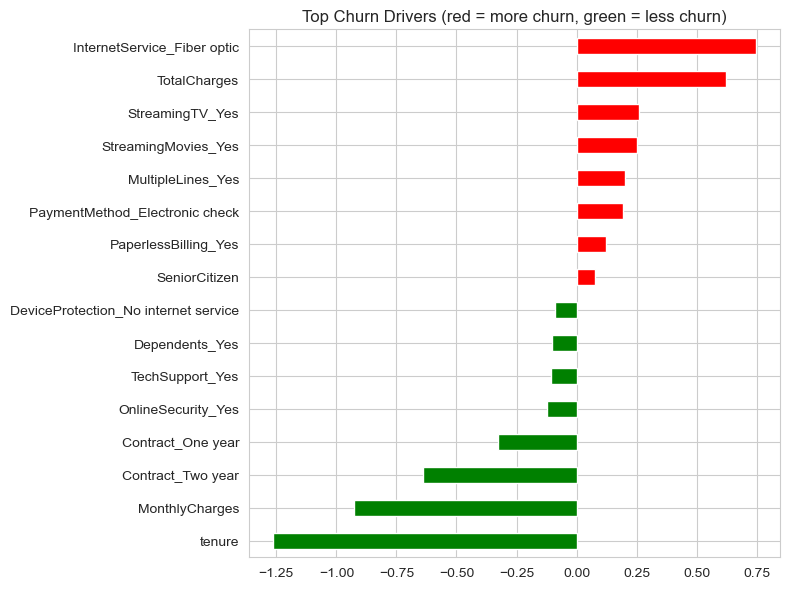

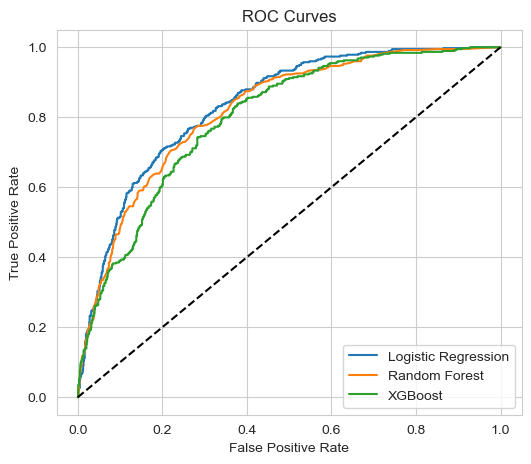

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

# 1. Top churn drivers from Logistic Regression
coef = pd.Series(lr.coef_[0], index=X.columns).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])

plt.figure(figsize=(8, 6))
top.plot(kind="barh", color=["green" if v < 0 else "red" for v in top])
plt.title("Top Churn Drivers (red = more churn, green = less churn)")
plt.tight_layout()
plt.savefig("churn_drivers.png", dpi=150)
plt.show()

# 2. ROC curves for all models
plt.figure(figsize=(6, 5))
for name, m in models.items():
    Xt = X_test_s if name == "Logistic Regression" else X_test
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(Xt)[:, 1])
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.title("ROC Curves")
plt.savefig("roc_curve.png", dpi=150)
plt.show()

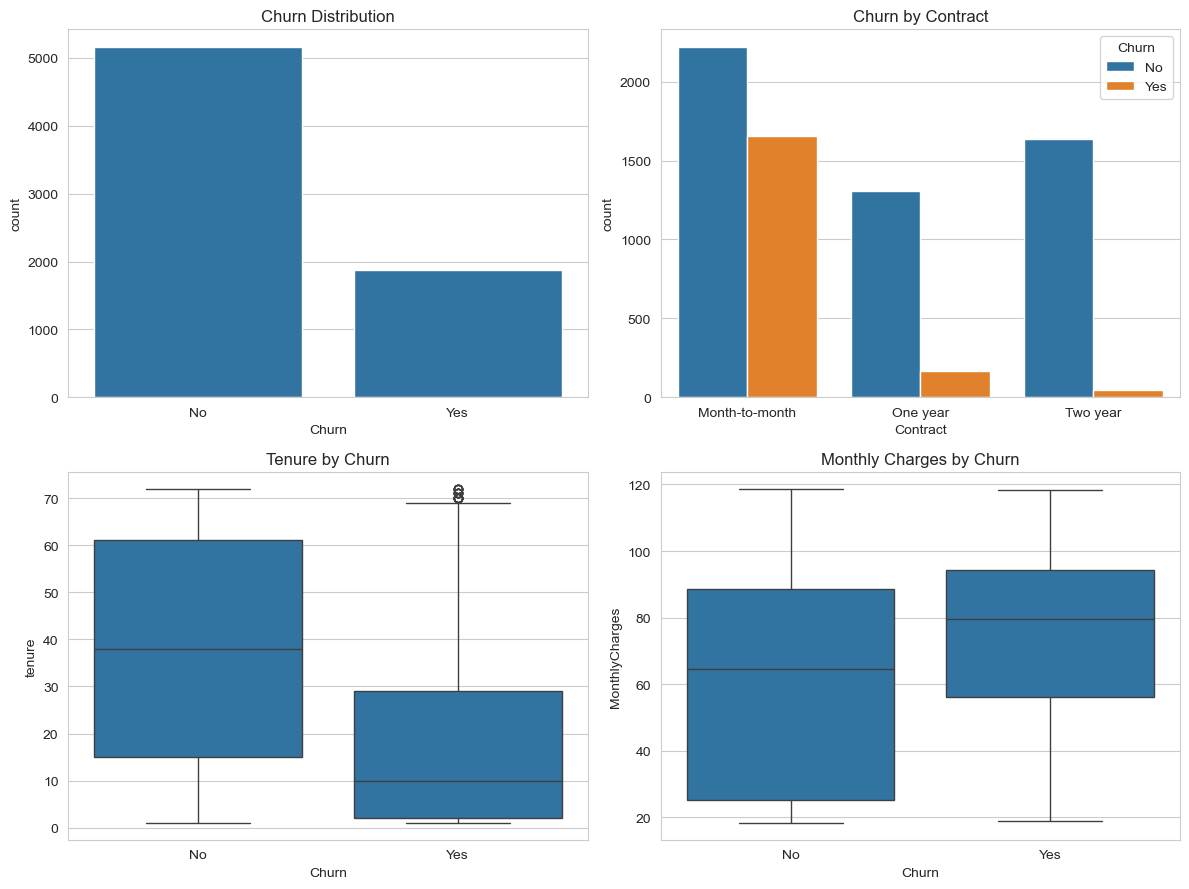

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
raw = pd.read_csv(url)
raw["TotalCharges"] = pd.to_numeric(raw["TotalCharges"], errors="coerce")
raw = raw.dropna(subset=["TotalCharges"])

sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.countplot(x="Churn", data=raw, ax=axes[0, 0])
axes[0, 0].set_title("Churn Distribution")

sns.countplot(x="Contract", hue="Churn", data=raw, ax=axes[0, 1])
axes[0, 1].set_title("Churn by Contract")

sns.boxplot(x="Churn", y="tenure", data=raw, ax=axes[1, 0])
axes[1, 0].set_title("Tenure by Churn")

sns.boxplot(x="Churn", y="MonthlyCharges", data=raw, ax=axes[1, 1])
axes[1, 1].set_title("Monthly Charges by Churn")

plt.tight_layout()
plt.savefig("eda_charts.png", dpi=150)
plt.show()